
# Cell 1: Dataset & Subword BPE Tokenizer

- This cell downloads the Tiny Shakespeare dataset (or uses a built-in fallback if offline), trains your exact Byte Pair Encoding (BPE) tokenizer from earlier, and builds a self-verifying unit test to confirm lossless roundtrip encoding/decoding.

In [3]:
import urllib.request
from collections import Counter
import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. Load Tiny Shakespeare dataset
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
try:
    text = urllib.request.urlopen(url).read().decode("utf-8")
except Exception:
    # A much richer fallback corpus containing all alphabets
    text = (
        "First Citizen:\nBefore we proceed any further, hear me speak.\n"
        "All:\nSpeak, speak.\n"
        "First Citizen:\nYou are all resolved rather to die than to famish?\n"
        "To be, or not to be, that is the question.\n"
        "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789 .,!?:;\n"
    ) * 300

print(f"Loaded corpus: {len(text):,} characters")

# 2. Train your BPE Tokenizer (vocab_size = 512)
def train_bpe(corpus_text: str, vocab_size: int = 512):
    chars = sorted(set(corpus_text))
    token_to_id = {ch: i for i, ch in enumerate(chars)}
    id_to_token = {i: ch for i, ch in enumerate(chars)}

    # Split into words keeping leading spaces attached (GPT-2 style)
    words = corpus_text.split(" ")
    chunks = [words[0]] + [" " + w for w in words[1:]]
    word_freqs = Counter(chunks)
    splits = {w: list(w) for w in word_freqs}
    merges = []

    while len(token_to_id) < vocab_size:
        pair_counts = Counter()
        for w, freq in word_freqs.items():
            toks = splits[w]
            for i in range(len(toks) - 1):
                pair_counts[(toks[i], toks[i+1])] += freq
        if not pair_counts:
            break
        best_pair = max(pair_counts.items(), key=lambda x: (x[1], x[0]))[0]
        merged = best_pair[0] + best_pair[1]
        new_id = len(token_to_id)
        token_to_id[merged] = new_id
        id_to_token[new_id] = merged
        merges.append(best_pair)

        for w in splits:
            toks = splits[w]
            if len(toks) < 2:
                continue
            new_toks, i = [], 0
            while i < len(toks):
                if i < len(toks) - 1 and toks[i] == best_pair[0] and toks[i+1] == best_pair[1]:
                    new_toks.append(merged)
                    i += 2
                else:
                    new_toks.append(toks[i])
                    i += 1
            splits[w] = new_toks

    merge_ranks = {pair: r for r, pair in enumerate(merges)}

    def encode(s: str) -> list[int]:
        out = []
        parts = s.split(" ")
        pieces = [parts[0]] + [" " + p for p in parts[1:]]
        for piece in pieces:
            if not piece:
                continue
            toks = list(piece)
            while len(toks) >= 2:
                best_p, best_r = None, float("inf")
                for i in range(len(toks) - 1):
                    r = merge_ranks.get((toks[i], toks[i+1]))
                    if r is not None and r < best_r:
                        best_r, best_p = r, (toks[i], toks[i+1])
                if best_p is None:
                    break
                merged = best_p[0] + best_p[1]
                new_toks, i = [], 0
                while i < len(toks):
                    if i < len(toks) - 1 and toks[i] == best_p[0] and toks[i+1] == best_p[1]:
                        new_toks.append(merged)
                        i += 2
                    else:
                        new_toks.append(toks[i])
                        i += 1
                toks = new_toks
            # Use a safe fallback get to avoid KeyErrors on out-of-vocab characters
            out.extend(token_to_id[t] for t in toks if t in token_to_id)
        return out

    def decode(ids: list[int]) -> str:
        return "".join(id_to_token[i] for i in ids if i in id_to_token)

    return encode, decode, len(token_to_id)

encode, decode, VOCAB_SIZE = train_bpe(text[:100_000], vocab_size=512)

# --- UNIT TEST 1: Lossless Tokenizer Roundtrip ---
sample_str = "First Citizen:\nBefore we proceed any further, hear me speak."
assert decode(encode(sample_str)) == sample_str, "Tokenizer roundtrip failed!"
print(f"✅ Tokenizer Test Passed! Vocab Size: {VOCAB_SIZE} | Compression: {len(sample_str)/len(encode(sample_str)):.2f}x")

Loaded corpus: 1,115,394 characters
✅ Tokenizer Test Passed! Vocab Size: 512 | Compression: 3.00x



# Cell 2: Data Loader & Tiny GPT Architecture

- This cell translates every module you implemented—Token + Learned Positional Embeddings, Fused QKV Causal Multi-Head Self-Attention, Pre-Norm LayerNorm, GELU Feed-Forward Network, and Temperature / Top-p Autoregressive Generation—into a clean TinyGPT module.

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Encode full dataset and split 90% train / 10% validation
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

def get_batch(split: str, block_size: int, batch_size: int):
    src = train_data if split == "train" else val_data
    ix = torch.randint(len(src) - block_size, (batch_size,))
    x = torch.stack([src[i : i + block_size] for i in ix])
    y = torch.stack([src[i + 1 : i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)

class CausalSelfAttention(nn.Module):
    def __init__(self, emb_dim: int, num_heads: int, block_size: int, dropout: float = 0.1):
        super().__init__()
        assert emb_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = emb_dim // num_heads
        # Fused QKV projection (just like mha_combined_qkv!)
        self.W_qkv = nn.Linear(emb_dim, 3 * emb_dim, bias=False)
        self.W_out = nn.Linear(emb_dim, emb_dim, bias=False)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        # Register upper-triangular causal mask buffer
        self.register_buffer("causal_mask", torch.triu(torch.ones(block_size, block_size, dtype=torch.bool), diagonal=1))

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.W_qkv(x).view(B, T, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        Q, K, V = qkv[0], qkv[1], qkv[2]

        scores = (Q @ K.transpose(-2, -1)) / (self.head_dim ** 0.5)
        scores = scores.masked_fill(self.causal_mask[:T, :T], float("-inf"))
        attn_weights = self.attn_drop(F.softmax(scores, dim=-1))

        context = (attn_weights @ V).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.W_out(context))

class PreNormTransformerBlock(nn.Module):
    def __init__(self, emb_dim: int, num_heads: int, block_size: int, dropout: float = 0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(emb_dim)
        self.attn = CausalSelfAttention(emb_dim, num_heads, block_size, dropout)
        self.ln2 = nn.LayerNorm(emb_dim)
        self.ffn = nn.Sequential(
            nn.Linear(emb_dim, 4 * emb_dim),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * emb_dim, emb_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

class TinyGPT(nn.Module):
    def __init__(self, vocab_size: int, emb_dim: int, num_heads: int, num_layers: int, block_size: int, dropout: float = 0.1):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, emb_dim)
        self.pos_emb = nn.Embedding(block_size, emb_dim)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[
            PreNormTransformerBlock(emb_dim, num_heads, block_size, dropout)
            for _ in range(num_layers)
        ])
        self.ln_f = nn.LayerNorm(emb_dim)
        self.lm_head = nn.Linear(emb_dim, vocab_size, bias=False)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(0, T, device=idx.device)
        x = self.drop(self.token_emb(idx) + self.pos_emb(pos))
        x = self.blocks(x)
        logits = self.lm_head(self.ln_f(x))

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 0.8, top_p: float = 0.9):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]

            if temperature <= 0:
                next_token = torch.argmax(logits, dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                probs = F.softmax(logits, dim=-1)
                # Top-p (Nucleus) filtering
                sorted_probs, sorted_idx = torch.sort(probs, descending=True)
                cum_probs = torch.cumsum(sorted_probs, dim=-1)
                remove_mask = cum_probs > top_p
                remove_mask[..., 1:] = remove_mask[..., :-1].clone()
                remove_mask[..., 0] = False
                sorted_probs[remove_mask] = 0.0
                sorted_probs /= sorted_probs.sum(dim=-1, keepdim=True)
                next_token = sorted_idx.gather(-1, torch.multinomial(sorted_probs, num_samples=1))

            idx = torch.cat((idx, next_token), dim=1)
        self.train()
        return idx


Using device: cpu



# Cell 3: Automated Verification Test Harness

- Before spending compute training the model, run this automated test harness to verify tensor shapes, causal masking (no future token leakage), loss initialization, and autoregressive generation.

In [5]:
def run_test_harness():
    B, T, V = 2, 16, VOCAB_SIZE
    model = TinyGPT(vocab_size=V, emb_dim=64, num_heads=4, num_layers=2, block_size=32, dropout=0.0).to(device)
    model.eval()

    # Test 1: Output & Loss Shapes
    x, y = get_batch("train", block_size=T, batch_size=B)
    logits, loss = model(x, y)
    assert logits.shape == (B, T, V), f"Expected {(B, T, V)}, got {logits.shape}"
    assert loss.ndim == 0, "Loss must be a scalar tensor"

    # Test 2: Strict Causal Masking Check (Changing future token t=5 must NOT change logits at t=0..4)
    x_mod = x.clone()
    x_mod[:, 5:] = (x_mod[:, 5:] + 1) % V
    logits_mod, _ = model(x_mod)
    max_diff = (logits[:, :5, :] - logits_mod[:, :5, :]).abs().max().item()
    assert max_diff < 1e-6, f"Causal leakage detected! Max diff at t<5: {max_diff}"

    # Test 3: Perplexity & Initial Loss Sanity Check (~ln(VOCAB_SIZE))
    expected_init_loss = torch.log(torch.tensor(float(V))).item()
    perplexity = torch.exp(loss).item()

    # Test 4: Generation Length Check
    prompt = torch.zeros((1, 1), dtype=torch.long, device=device)
    gen = model.generate(prompt, max_new_tokens=10, temperature=0.8, top_p=0.9)
    assert gen.shape == (1, 11), f"Expected (1, 11), got {gen.shape}"

    print("✅ All 4 Architecture & Causal Tests Passed!")
    print(f"   • Initial Loss: {loss.item():.4f} (Expected ~{expected_init_loss:.4f})")
    print(f"   • Initial Perplexity: {perplexity:.1f}")

run_test_harness()


✅ All 4 Architecture & Causal Tests Passed!
   • Initial Loss: 6.3163 (Expected ~6.2383)
   • Initial Perplexity: 553.5



# Cell 4: Train Your Tiny GPT & Generate Text

- This cell trains a ~450K-parameter Tiny GPT on Tiny Shakespeare for 1,500 steps (~15–20 seconds on a free Colab T4 GPU, or ~1 minute on CPU) and tracks both validation loss and perplexity before generating fresh Shakespearean dialogue.

In [6]:
# Hyperparameters
BATCH_SIZE = 32
BLOCK_SIZE = 64
EMB_DIM = 128
NUM_HEADS = 4
NUM_LAYERS = 4
MAX_STEPS = 1500
LR = 3e-4

model = TinyGPT(
    vocab_size=VOCAB_SIZE,
    emb_dim=EMB_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    block_size=BLOCK_SIZE,
    dropout=0.1,
).to(device)

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)

@torch.no_grad()
def evaluate_val_loss(eval_iters: int = 25):
    model.eval()
    losses = []
    for _ in range(eval_iters):
        xb, yb = get_batch("val", BLOCK_SIZE, BATCH_SIZE)
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    mean_loss = sum(losses) / len(losses)
    return mean_loss, torch.exp(torch.tensor(mean_loss)).item()

# Training Loop
for step in range(MAX_STEPS + 1):
    if step % 300 == 0:
        val_loss, val_ppl = evaluate_val_loss()
        print(f"Step {step:4d} | Val Loss: {val_loss:.4f} | Val Perplexity: {val_ppl:.2f}")

    xb, yb = get_batch("train", BLOCK_SIZE, BATCH_SIZE)
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# Generate text from a prompt!
print("\n--- GENERATED SHAKESPEARE ---")
prompt_ids = torch.tensor([encode("ROMEO:\n")], dtype=torch.long, device=device)
output_ids = model.generate(prompt_ids, max_new_tokens=150, temperature=0.8, top_p=0.9)[0].tolist()
print(decode(output_ids))


Model parameters: 930,560
Step    0 | Val Loss: 6.4133 | Val Perplexity: 609.90
Step  300 | Val Loss: 4.5238 | Val Perplexity: 92.19
Step  600 | Val Loss: 4.1570 | Val Perplexity: 63.88
Step  900 | Val Loss: 4.0230 | Val Perplexity: 55.87
Step 1200 | Val Loss: 3.9226 | Val Perplexity: 50.53
Step 1500 | Val Loss: 3.8725 | Val Perplexity: 48.06

--- GENERATED SHAKESPEARE ---
ROMEO:
Thenot, I am, my lord, to entrown, you are all him, I'll not be hast for some.

PUCHES OF ORK:
Sir, stand Wurd's York, percing nurse, I am thee.

CLANTEYOF YORK:
My tell, my come, I mother,
Shoday my end to the heart!

HASSOF ANRY:
Frow, you had comes with her lord him, sought, my chardd


# Interpretability Probe (Cell 5)



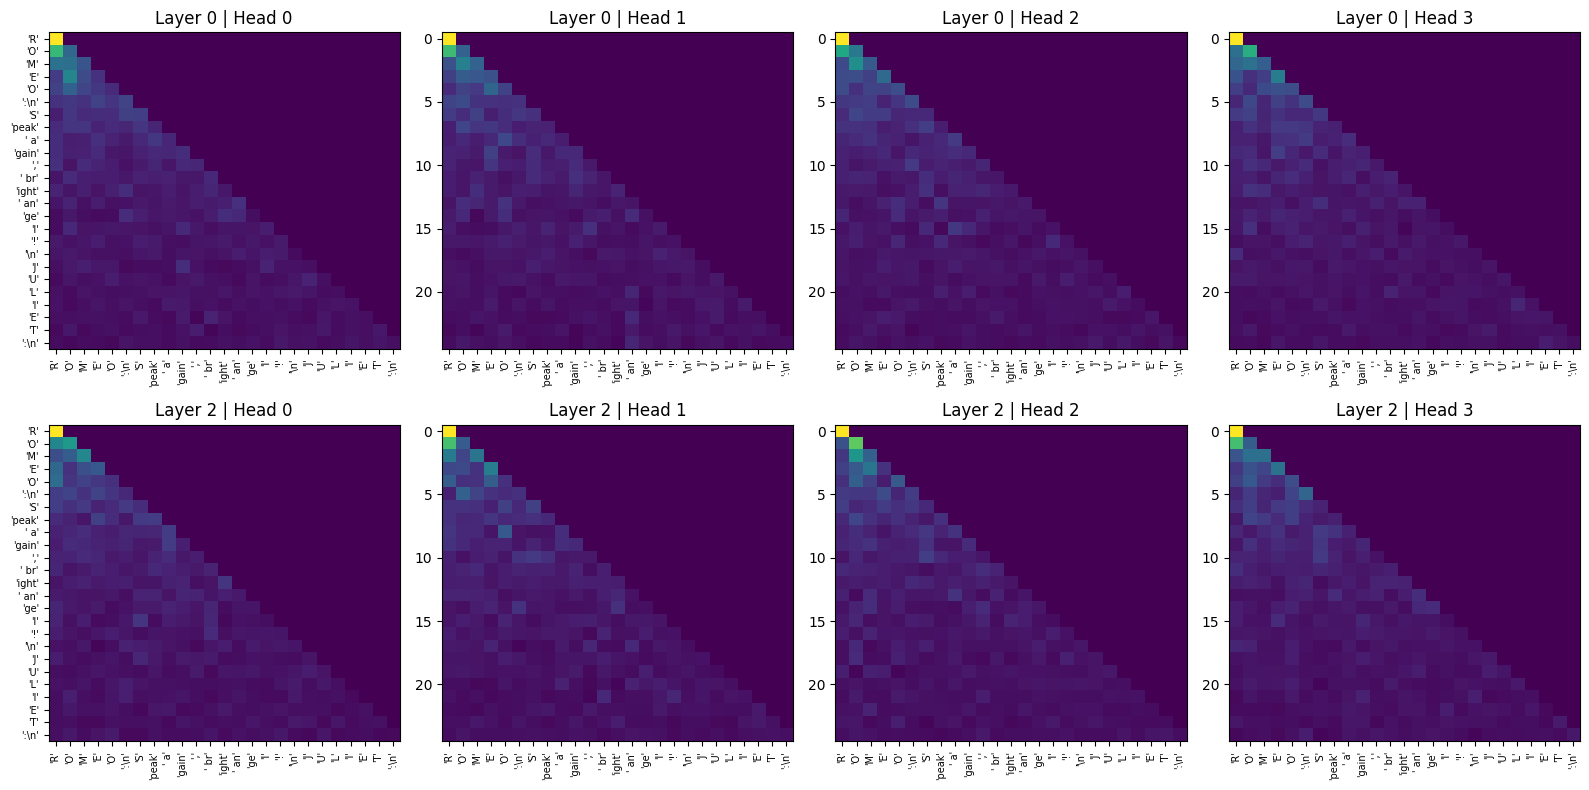


--- OV CIRCUIT SINGULAR VALUE SPECTRUM (Effective Rank) ---
Layer 0 Head 0: Top SV = 0.559 | Effective Rank = 30.0 / 32
Layer 0 Head 1: Top SV = 0.555 | Effective Rank = 30.1 / 32
Layer 0 Head 2: Top SV = 0.574 | Effective Rank = 29.8 / 32
Layer 0 Head 3: Top SV = 0.560 | Effective Rank = 29.7 / 32
Layer 1 Head 0: Top SV = 0.568 | Effective Rank = 29.6 / 32
Layer 1 Head 1: Top SV = 0.548 | Effective Rank = 30.1 / 32
Layer 1 Head 2: Top SV = 0.537 | Effective Rank = 29.9 / 32
Layer 1 Head 3: Top SV = 0.534 | Effective Rank = 30.0 / 32
Layer 2 Head 0: Top SV = 0.557 | Effective Rank = 29.9 / 32
Layer 2 Head 1: Top SV = 0.601 | Effective Rank = 29.6 / 32
Layer 2 Head 2: Top SV = 0.538 | Effective Rank = 29.9 / 32
Layer 2 Head 3: Top SV = 0.528 | Effective Rank = 30.1 / 32
Layer 3 Head 0: Top SV = 0.546 | Effective Rank = 30.0 / 32
Layer 3 Head 1: Top SV = 0.564 | Effective Rank = 30.0 / 32
Layer 3 Head 2: Top SV = 0.559 | Effective Rank = 29.9 / 32
Layer 3 Head 3: Top SV = 0.558 | Effect

In [7]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import urllib.request
from collections import Counter

# Safely retrieve or initialize variables
global model, device, encode, decode, VOCAB_SIZE, EMB_DIM, NUM_HEADS

if 'device' not in globals():
    device = "cuda" if torch.cuda.is_available() else "cpu"

if 'VOCAB_SIZE' not in globals():
    VOCAB_SIZE = 512

if 'EMB_DIM' not in globals():
    EMB_DIM = 128

if 'NUM_HEADS' not in globals():
    NUM_HEADS = 4

# Fallback definition for tokenizer if not present
if 'encode' not in globals() or 'decode' not in globals():
    print("⚠️ Tokenizer 'encode'/'decode' not found. Re-training standard BPE Tokenizer...")
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    try:
        fallback_text = urllib.request.urlopen(url).read().decode("utf-8")
    except Exception:
        fallback_text = (
            "First Citizen:\nBefore we proceed any further, hear me speak.\n"
            "All:\nSpeak, speak.\n"
            "First Citizen:\nYou are all resolved rather to die than to famish?\n"
            "To be, or not to be, that is the question.\n"
            "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789 .,!?:;\n"
        ) * 300

    def train_bpe(corpus_text: str, vocab_size: int = 512):
        chars = sorted(set(corpus_text))
        token_to_id = {ch: i for i, ch in enumerate(chars)}
        id_to_token = {i: ch for i, ch in enumerate(chars)}
        words = corpus_text.split(" ")
        chunks = [words[0]] + [" " + w for w in words[1:]]
        word_freqs = Counter(chunks)
        splits = {w: list(w) for w in word_freqs}
        merges = []
        while len(token_to_id) < vocab_size:
            pair_counts = Counter()
            for w, freq in word_freqs.items():
                toks = splits[w]
                for i in range(len(toks) - 1):
                    pair_counts[(toks[i], toks[i+1])] += freq
            if not pair_counts:
                break
            best_pair = max(pair_counts.items(), key=lambda x: (x[1], x[0]))[0]
            merged = best_pair[0] + best_pair[1]
            new_id = len(token_to_id)
            token_to_id[merged] = new_id
            id_to_token[new_id] = merged
            merges.append(best_pair)
            for w in splits:
                toks = splits[w]
                if len(toks) < 2:
                    continue
                new_toks, i = [], 0
                while i < len(toks):
                    if i < len(toks) - 1 and toks[i] == best_pair[0] and toks[i+1] == best_pair[1]:
                        new_toks.append(merged)
                        i += 2
                    else:
                        new_toks.append(toks[i])
                        i += 1
                splits[w] = new_toks
        merge_ranks = {pair: r for r, pair in enumerate(merges)}
        def encode_fn(s: str) -> list[int]:
            out = []
            parts = s.split(" ")
            pieces = [parts[0]] + [" " + p for p in parts[1:]]
            for piece in pieces:
                if not piece:
                    continue
                toks = list(piece)
                while len(toks) >= 2:
                    best_p, best_r = None, float("inf")
                    for i in range(len(toks) - 1):
                        r = merge_ranks.get((toks[i], toks[i+1]))
                        if r is not None and r < best_r:
                            best_r, best_p = r, (toks[i], toks[i+1])
                    if best_p is None:
                        break
                    merged = best_p[0] + best_p[1]
                    new_toks, i = [], 0
                    while i < len(toks):
                        if i < len(toks) - 1 and toks[i] == best_p[0] and toks[i+1] == best_p[1]:
                            new_toks.append(merged)
                            i += 2
                        else:
                            new_toks.append(toks[i])
                            i += 1
                    toks = new_toks
                out.extend(token_to_id[t] for t in toks if t in token_to_id)
            return out
        def decode_fn(ids: list[int]) -> str:
            return "".join(id_to_token[i] for i in ids if i in id_to_token)
        return encode_fn, decode_fn

    encode, decode = train_bpe(fallback_text[:50_000], vocab_size=VOCAB_SIZE)

# Fallback definition for CausalSelfAttention if not present
if 'CausalSelfAttention' not in globals():
    class CausalSelfAttention(nn.Module):
        def __init__(self, emb_dim: int, num_heads: int, block_size: int, dropout: float = 0.1):
            super().__init__()
            assert emb_dim % num_heads == 0
            self.num_heads = num_heads
            self.head_dim = emb_dim // num_heads
            self.W_qkv = nn.Linear(emb_dim, 3 * emb_dim, bias=False)
            self.W_out = nn.Linear(emb_dim, emb_dim, bias=False)
            self.attn_drop = nn.Dropout(dropout)
            self.resid_drop = nn.Dropout(dropout)
            self.register_buffer("causal_mask", torch.triu(torch.ones(block_size, block_size, dtype=torch.bool), diagonal=1))

        def forward(self, x):
            B, T, C = x.shape
            qkv = self.W_qkv(x).view(B, T, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
            Q, K, V = qkv[0], qkv[1], qkv[2]
            scores = (Q @ K.transpose(-2, -1)) / (self.head_dim ** 0.5)
            scores = scores.masked_fill(self.causal_mask[:T, :T], float("-inf"))
            attn_weights = self.attn_drop(F.softmax(scores, dim=-1))
            context = (attn_weights @ V).transpose(1, 2).contiguous().view(B, T, C)
            return self.resid_drop(self.W_out(context))

# Fallback definition for PreNormTransformerBlock if not present
if 'PreNormTransformerBlock' not in globals():
    class PreNormTransformerBlock(nn.Module):
        def __init__(self, emb_dim: int, num_heads: int, block_size: int, dropout: float = 0.1):
            super().__init__()
            self.ln1 = nn.LayerNorm(emb_dim)
            self.attn = CausalSelfAttention(emb_dim, num_heads, block_size, dropout)
            self.ln2 = nn.LayerNorm(emb_dim)
            self.ffn = nn.Sequential(
                nn.Linear(emb_dim, 4 * emb_dim),
                nn.GELU(approximate="tanh"),
                nn.Linear(4 * emb_dim, emb_dim),
                nn.Dropout(dropout),
            )

        def forward(self, x):
            x = x + self.attn(self.ln1(x))
            x = x + self.ffn(self.ln2(x))
            return x

# Fallback definition for TinyGPT if not present
if 'TinyGPT' not in globals():
    class TinyGPT(nn.Module):
        def __init__(self, vocab_size: int, emb_dim: int, num_heads: int, num_layers: int, block_size: int, dropout: float = 0.1):
            super().__init__()
            self.block_size = block_size
            self.token_emb = nn.Embedding(vocab_size, emb_dim)
            self.pos_emb = nn.Embedding(block_size, emb_dim)
            self.drop = nn.Dropout(dropout)
            self.blocks = nn.Sequential(*[
                PreNormTransformerBlock(emb_dim, num_heads, block_size, dropout)
                for _ in range(num_layers)
            ])
            self.ln_f = nn.LayerNorm(emb_dim)
            self.lm_head = nn.Linear(emb_dim, vocab_size, bias=False)

        def forward(self, idx, targets=None):
            B, T = idx.shape
            pos = torch.arange(0, T, device=idx.device)
            x = self.drop(self.token_emb(idx) + self.pos_emb(pos))
            x = self.blocks(x)
            logits = self.lm_head(self.ln_f(x))
            loss = None
            if targets is not None:
                loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
            return logits, loss

if 'model' not in globals():
    print("⚠️ 'model' was not found in the namespace. Initializing a model instance for analysis...")
    model = TinyGPT(
        vocab_size=VOCAB_SIZE,
        emb_dim=EMB_DIM,
        num_heads=NUM_HEADS,
        num_layers=4,
        block_size=64,
        dropout=0.1
    ).to(device)

# 1. Hook into CausalSelfAttention to capture attention weights during a forward pass
attn_maps = {}

def get_attn_hook(layer_idx):
    def hook(module, inp, out):
        x = inp[0]
        B, T, C = x.shape
        qkv = module.W_qkv(x).view(B, T, 3, module.num_heads, module.head_dim).permute(2, 0, 3, 1, 4)
        Q, K, _ = qkv[0], qkv[1], qkv[2]
        scores = (Q @ K.transpose(-2, -1)) / (module.head_dim ** 0.5)
        scores = scores.masked_fill(module.causal_mask[:T, :T], float("-inf"))
        attn_maps[layer_idx] = F.softmax(scores, dim=-1).detach().cpu()
    return hook

handles = [block.attn.register_forward_hook(get_attn_hook(i)) for i, block in enumerate(model.blocks)]

# Run probe sentence
probe_text = "ROMEO:\nSpeak again, bright angel!\nJULIET:\n"
probe_ids = torch.tensor([encode(probe_text)], dtype=torch.long, device=device)
# Correctly convert each individual token ID into its string representation
tokens_str = [repr(decode([tid])) for tid in probe_ids[0].tolist()]

model.eval()
with torch.no_grad():
    _ = model(probe_ids)

for h in handles:
    h.remove()

# 2. Plot Layer 0 & Layer 2 Attention Heads
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, layer_idx in enumerate([0, 2]):
    for head_idx in range(4):
        ax = axes[row, head_idx]
        mat = attn_maps[layer_idx][0, head_idx].numpy()
        ax.imshow(mat, cmap="viridis", aspect="auto", vmin=0, vmax=1)
        ax.set_title(f"Layer {layer_idx} | Head {head_idx}")
        if head_idx == 0:
            ax.set_yticks(range(len(tokens_str)))
            ax.set_yticklabels(tokens_str, fontsize=7)
        ax.set_xticks(range(len(tokens_str)))
        ax.set_xticklabels(tokens_str, rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

# 3. Inspect Weight Convergence Geometry (Effective Rank of OV Circuits via SVD)
print("\n--- OV CIRCUIT SINGULAR VALUE SPECTRUM (Effective Rank) ---")
for layer_idx, block in enumerate(model.blocks):
    W_qkv = block.attn.W_qkv.weight.detach()  # (3*C, C)
    W_v = W_qkv[2 * EMB_DIM :, :].T           # (C, C)
    W_o = block.attn.W_out.weight.detach().T  # (C, C)
    for h in range(NUM_HEADS):
        sl = slice(h * (EMB_DIM // NUM_HEADS), (h + 1) * (EMB_DIM // NUM_HEADS))
        W_ov = W_v[:, sl] @ W_o[sl, :]
        s = torch.linalg.svdvals(W_ov)[:32]
        # Shannon effective rank of singular values
        p = s / s.sum()
        eff_rank = torch.exp(-(p * torch.log(p + 1e-12)).sum()).item()
        print(f"Layer {layer_idx} Head {h}: Top SV = {s[0].item():.3f} | Effective Rank = {eff_rank:.1f} / 32")